<a href="https://colab.research.google.com/github/Eryk360779/useful_programs/blob/main/colab_intro1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colab Intro

## Zadanie 2

The Taylor series of a *real* or *complex-valued* function $f(x)$, that is infinitely differentiable at a real or complex number a, is the power series:

$$
f(x)=\sum_{n=0}^{\infty}\frac{f^{(n)}(a)}{n!}(x-a)^n
$$

Here, $n!$ denotes the factorial of $n$. The function $f^{(n)} (a)$ denotes the ***nth derivative*** of f evaluated at the point $a$. The derivative of order zero of f is defined to be $f$ itself and $(x − a)^0$ and $0!$ are both defined to be $1$. This series can be written by using sigma notation, as in the right side formula. The corresponding Taylor polynomial of degree n is

$$
T_n(x)=\sum_{k=0}^{n}\frac{f^{(k)}(a)}{k!}(x-a)^k
$$

When $a = 0$, the series is also called a ***Maclaurin series*** and takes the form:

$$
f(x)=\sum_{n=0}^{\infty}\frac{f^{(n)}(0)}{n!}x^n
$$

## Zadanie 3

In [ ]:
2+2

4

## Zadanie 4

In [ ]:
import math

result = math.pi ** math.pi

print(result)

36.4621596072079


## Zadanie 5

In [ ]:
total = sum(n**2 for n in range(1, 101))

print("The sum of squares from 1 to 100 is:", total)

The sum of squares from 1 to 100 is: 338350


## Zadanie 6

In [ ]:


with open("wynik.txt", "w", encoding="utf-8") as f:
    f.write(str(total))

## Zadanie 7 i 8

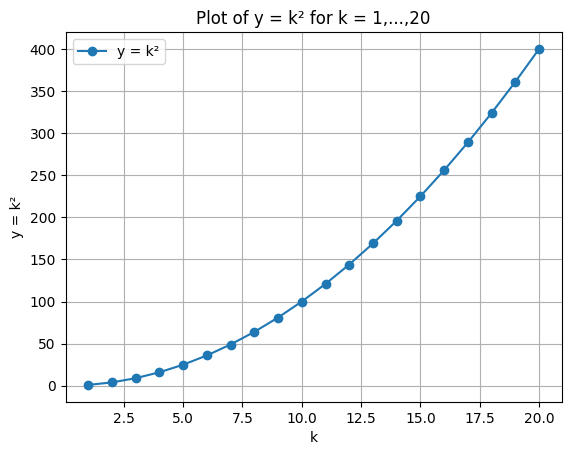

In [ ]:
import matplotlib.pyplot as plt

# Generate data
k = list(range(1, 21))
y = [n**2 for n in k]

# Create the plot
plt.plot(k, y, marker='o', label='y = k²')

# Add title and axis labels
plt.xlabel('k')
plt.ylabel('y = k²')
plt.title('Plot of y = k² for k = 1,...,20')

# Add grid and legend
plt.grid(True)
plt.legend()

# Save the plot as a PNG image
plt.savefig('wykres.png', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()

## Zadanie 9

Animation saved as video.mp4


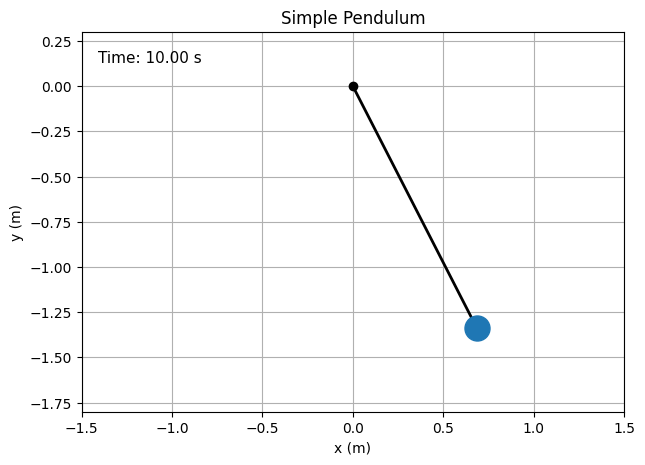

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

# -----------------------------
# 1. Pendulum parameters
# -----------------------------
g = 9.81             # Gravitational acceleration (m/s^2)
L = 1.5              # Pendulum length (m)
theta0 = np.radians(30)  # Initial angle (radians)

# Angular frequency (small-angle approximation)
omega = np.sqrt(g / L)

# -----------------------------
# 2. Animation parameters
# -----------------------------
fps = 30
duration = 10         # Duration of video (seconds)
frames = fps * duration

# Time values
t = np.linspace(0, duration, frames)

# Pendulum angle over time
theta = theta0 * np.cos(omega * t)

# Bob coordinates
x = L * np.sin(theta)
y = -L * np.cos(theta)

# -----------------------------
# 3. Create the figure
# -----------------------------
fig, ax = plt.subplots(figsize=(7, 7))

ax.set_xlim(-L, L)
ax.set_ylim(-L - 0.3, 0.3)
ax.set_aspect('equal')
ax.set_title("Simple Pendulum")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.grid(True)

# Pivot point
ax.plot(0, 0, 'ko', markersize=6)

# Pendulum rod
rod, = ax.plot([], [], 'k-', linewidth=2)

# Pendulum bob
bob, = ax.plot([], [], 'o', markersize=18)

# Information displayed during animation
time_text = ax.text(
    0.03, 0.95, "",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top"
)

# -----------------------------
# 4. Initialize animation
# -----------------------------
def init():
    rod.set_data([], [])
    bob.set_data([], [])
    time_text.set_text("")
    return rod, bob, time_text

# -----------------------------
# 5. Update each animation frame
# -----------------------------
def update(i):
    # Update rod position
    rod.set_data([0, x[i]], [0, y[i]])

    # Update bob position
    bob.set_data([x[i]], [y[i]])

    # Update elapsed time
    time_text.set_text(f"Time: {t[i]:.2f} s")

    return rod, bob, time_text

# Create animation
ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    init_func=init,
    interval=1000 / fps,
    blit=True
)

# -----------------------------
# 6. Save animation as MP4
# -----------------------------
writer = FFMpegWriter(
    fps=fps,
    bitrate=1800,
    metadata={"title": "Simple Pendulum Animation"}
)

ani.save("video.mp4", writer=writer)

print("Animation saved as video.mp4")

# Display animation
plt.show()

## Zadanie 10

In [ ]:
import cv2
from PIL import Image

# Open the MP4 video
video = cv2.VideoCapture("video.mp4")

frames = []

# Read video frames
while True:
    success, frame = video.read()

    if not success:
        break

    # Convert BGR (OpenCV) to RGB (Pillow)
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Convert frame to a Pillow image
    frames.append(Image.fromarray(frame))

video.release()

# Save frames as an animated GIF
if frames:
    frames[0].save(
        "video.gif",
        save_all=True,
        append_images=frames[1:],
        duration=67,  # Approximately 15 FPS
        loop=0
    )
    print("Conversion complete: video.gif")
else:
    print("Error: No frames found. Check that video.mp4 exists.")

Conversion complete: video.gif


## Zadanie 11

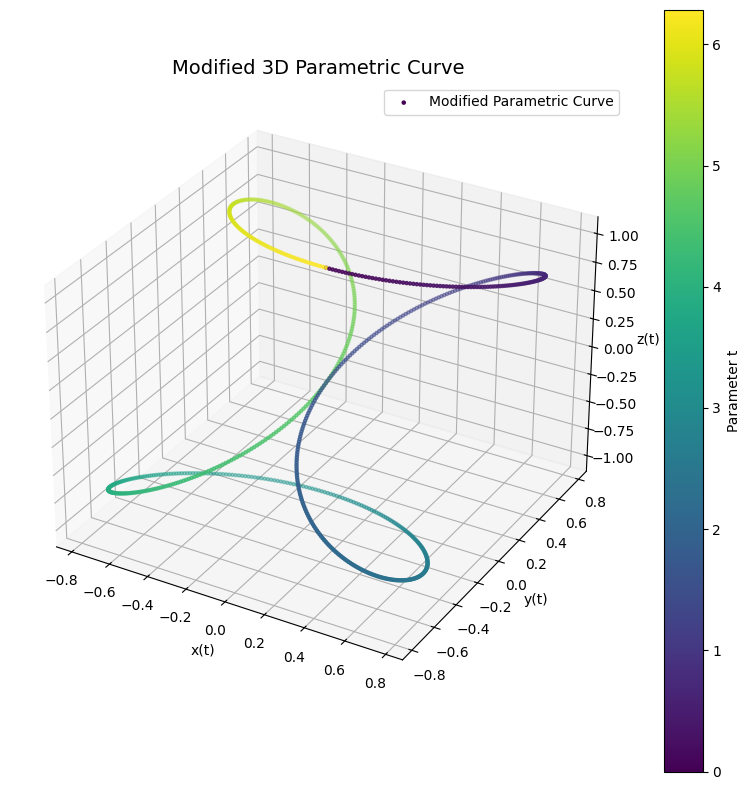

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parametric equations
t = np.linspace(0, 2 * np.pi, 800)

x = np.sin(2 * t) * np.cos(t)
y = np.sin(2 * t) * np.sin(t)
z = np.cos(t)

# Create the 3D plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

# Plot the curve
ax.scatter(
    x, y, z,
    c=t,
    cmap="viridis",
    s=5,
    label="Modified Parametric Curve"
)

# Titles and labels
ax.set_title("Modified 3D Parametric Curve", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")

# Add color bar and legend
fig.colorbar(
    plt.cm.ScalarMappable(
        cmap="viridis",
        norm=plt.Normalize(t.min(), t.max())
    ),
    ax=ax,
    label="Parameter t"
)

ax.legend()

# Improve layout and save the image
plt.tight_layout()
plt.savefig("parametric_curve.png", dpi=300, bbox_inches="tight")

# Display the plot
plt.show()